In [4]:
import torch 
print(torch.__version__)

2.8.0


In [5]:
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import matplotlib.pyplot as plt

torch.manual_seed(0)   # makes results repeatable

days = pd.read_csv("data/days.csv", index_col=0, parse_dates=True)

# Split by time: learn from 2006–2009, test on 2010
train = days[days.index < "2010-01-01"]
test = days[days.index >= "2010-01-01"]

# Scale to roughly 0–1. Neural networks train better on small numbers
SCALE = train.values.max()
x_train = torch.tensor(train.values / SCALE, dtype=torch.float32)
x_test = torch.tensor(test.values / SCALE, dtype=torch.float32)

print("SCALE (kW):", SCALE)
print(x_train.shape, x_test.shape)

SCALE (kW): 6.560533333333334
torch.Size([1103, 24]) torch.Size([314, 24])


In [7]:
class VAE(nn.Module):
    def __init__(self, latent_dim=4, hidden=64):
        super().__init__()
        # Encoder: 24 numbers -> hidden features
        self.encoder = nn.Sequential(
            nn.Linear(24, hidden), nn.ReLU(),
            nn.Linear(hidden, hidden), nn.ReLU(),
        )
        # Two "heads": the centre (mu) and the uncertainty (logvar) of each latent number
        self.to_mu = nn.Linear(hidden, latent_dim)
        self.to_logvar = nn.Linear(hidden, latent_dim)
        # Decoder: latent numbers -> 24 numbers
        self.decoder = nn.Sequential(
            nn.Linear(latent_dim, hidden), nn.ReLU(),
            nn.Linear(hidden, hidden), nn.ReLU(),
            nn.Linear(hidden, 24),
        )

    def encode(self, x):
        h = self.encoder(x)
        return self.to_mu(h), self.to_logvar(h)

    def decode(self, z):
        return self.decoder(z)

    def forward(self, x):
        mu, logvar = self.encode(x)
        std = torch.exp(0.5 * logvar)
        z = mu + std * torch.randn_like(std)   # the "reparameterisation trick"
        return self.decode(z), mu, logvar

In [8]:
def vae_loss(x, x_hat, mu, logvar, beta):
    # 1. Reconstruction: how different is the rebuilt day from the real one?
    recon = ((x - x_hat) ** 2).sum(dim=1).mean()
    # 2. KL divergence: how far are the latent codes from plain random noise N(0, 1)?
    kl = (-0.5 * (1 + logvar - mu**2 - logvar.exp()).sum(dim=1)).mean()
    return recon + beta * kl, recon, kl

In [9]:
model = VAE()
x_hat, mu, logvar = model(x_train[:5])       # push 5 real days through the untrained model
loss, recon, kl = vae_loss(x_train[:5], x_hat, mu, logvar, beta=0.003)
print("output shape:", x_hat.shape)
print("mu shape:", mu.shape)
print("loss:", loss.item())

output shape: torch.Size([5, 24])
mu shape: torch.Size([5, 4])
loss: 2.479785919189453


In [10]:
BETA = 0.003
model = VAE()
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)
loader = torch.utils.data.DataLoader(x_train, batch_size=64, shuffle=True)

history = []
for epoch in range(300):
    model.train()
    for xb in loader:
        x_hat, mu, logvar = model(xb)
        loss, recon, kl = vae_loss(xb, x_hat, mu, logvar, BETA)
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

    # check on the test year (no learning here)
    model.eval()
    with torch.no_grad():
        x_hat, mu, logvar = model(x_test)
        _, test_recon, test_kl = vae_loss(x_test, x_hat, mu, logvar, BETA)
    history.append((recon.item(), test_recon.item(), kl.item()))

    if epoch % 25 == 0:
        print(f"epoch {epoch:3d} | train recon {recon.item():.4f} | test recon {test_recon.item():.4f} | KL {kl.item():.2f}")

torch.save(model.state_dict(), "vae_baseline.pt")

epoch   0 | train recon 0.5291 | test recon 0.4235 | KL 0.13
epoch  25 | train recon 0.1601 | test recon 0.1235 | KL 7.14
epoch  50 | train recon 0.1367 | test recon 0.1005 | KL 8.70
epoch  75 | train recon 0.1114 | test recon 0.1002 | KL 7.87
epoch 100 | train recon 0.0829 | test recon 0.1008 | KL 7.57
epoch 125 | train recon 0.0990 | test recon 0.1000 | KL 6.84
epoch 150 | train recon 0.1055 | test recon 0.1030 | KL 7.67
epoch 175 | train recon 0.0991 | test recon 0.1036 | KL 7.51
epoch 200 | train recon 0.1134 | test recon 0.1034 | KL 7.65
epoch 225 | train recon 0.0877 | test recon 0.1029 | KL 6.86
epoch 250 | train recon 0.0838 | test recon 0.1019 | KL 8.80
epoch 275 | train recon 0.0957 | test recon 0.1039 | KL 8.13


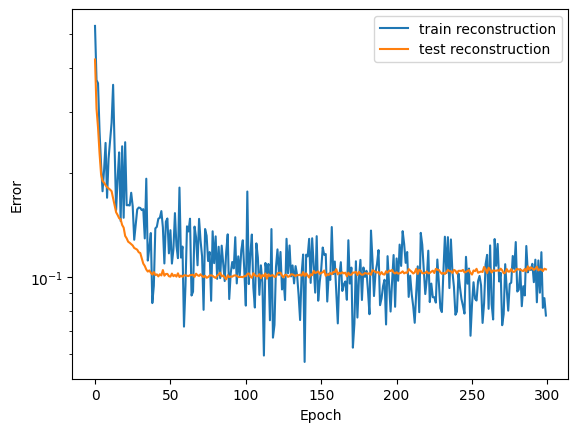

In [11]:
h = np.array(history)
plt.plot(h[:, 0], label="train reconstruction")
plt.plot(h[:, 1], label="test reconstruction")
plt.xlabel("Epoch")
plt.ylabel("Error")
plt.yscale("log")
plt.legend()
plt.show()

In [14]:
BETA = 0.003
model = VAE()
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)
loader = torch.utils.data.DataLoader(x_train, batch_size=64, shuffle=True)

history = []
for epoch in range(150):                         # CHANGED: 300 -> 150
    model.train()
    epoch_recon = 0.0                            # NEW: running total for this epoch
    for xb in loader:
        x_hat, mu, logvar = model(xb)
        loss, recon, kl = vae_loss(xb, x_hat, mu, logvar, BETA)
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
        epoch_recon += recon.item() * len(xb)    # NEW: add up this batch's error
    epoch_recon /= len(x_train)                  # NEW: average over all training days

    # check on the test year (no learning here)
    model.eval()
    with torch.no_grad():
        x_hat, mu, logvar = model(x_test)
        _, test_recon, test_kl = vae_loss(x_test, x_hat, mu, logvar, BETA)
    history.append((epoch_recon, test_recon.item(), kl.item()))   # CHANGED: epoch_recon

    if epoch % 25 == 0:
        print(f"epoch {epoch:3d} | train recon {epoch_recon:.4f} | test recon {test_recon.item():.4f} | KL {kl.item():.2f}")   # CHANGED: epoch_recon

torch.save(model.state_dict(), "vae_baseline.pt")

epoch   0 | train recon 0.8263 | test recon 0.3722 | KL 0.10
epoch  25 | train recon 0.1724 | test recon 0.1323 | KL 6.96
epoch  50 | train recon 0.1278 | test recon 0.1105 | KL 6.75
epoch  75 | train recon 0.1178 | test recon 0.1070 | KL 7.31
epoch 100 | train recon 0.1135 | test recon 0.1041 | KL 7.39
epoch 125 | train recon 0.1111 | test recon 0.1030 | KL 7.92


In [15]:
print("Train days: mean %.2f kW, spread %.2f kW" % (train.values.mean(), train.values.std()))
print("Test days:  mean %.2f kW, spread %.2f kW" % (test.values.mean(), test.values.std()))

Train days: mean 1.10 kW, spread 0.93 kW
Test days:  mean 1.06 kW, spread 0.78 kW
